Sample rate: 48000, Duration: 231.76 seconds


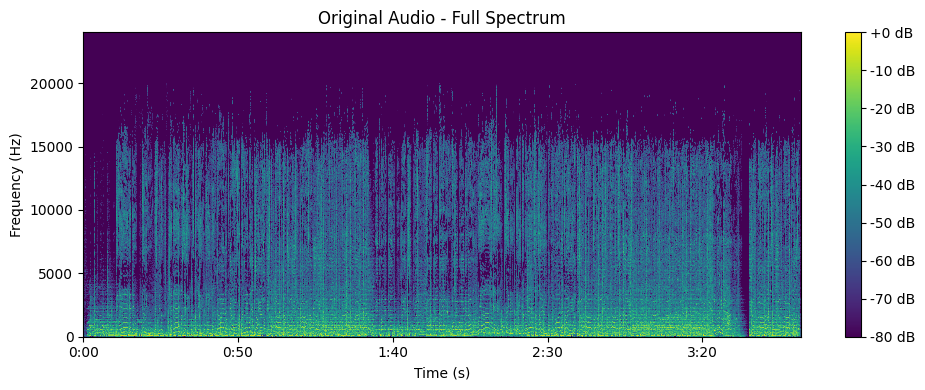

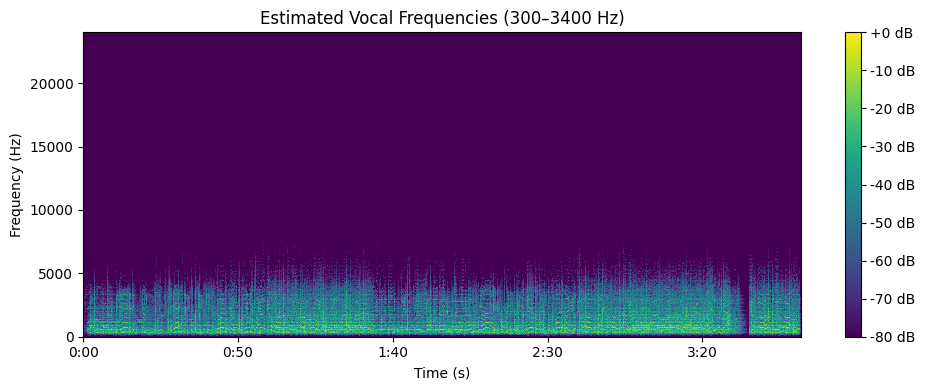

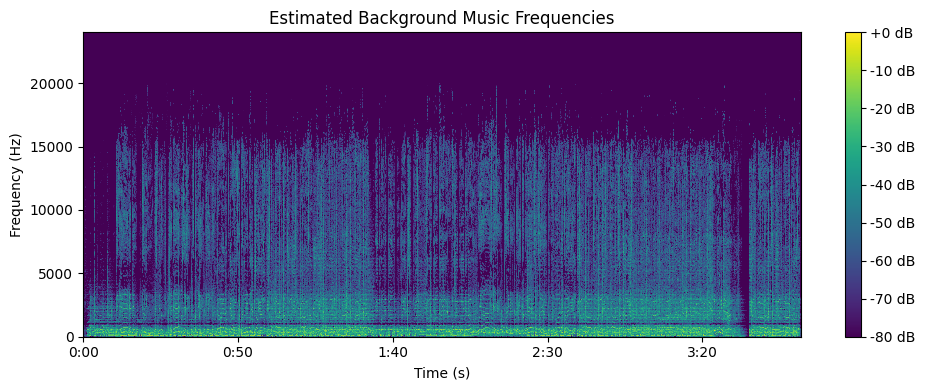

Audio processing completed successfully!
Saved: filtered_vocals.wav
Saved: estimated_background.wav


In [5]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from scipy.signal import butter, lfilter

# --- 1. Load Audio File ---
filename = r"D:\SEM_5\DSIP\DSIP_practical\open_ended_problem_4\Tu Hi Disda.mpeg"

y, sr = librosa.load(filename, sr=None)

print(f"Sample rate: {sr}, Duration: {len(y) / sr:.2f} seconds")


# --- 2. Bandpass Filter for Vocals (Speech: 300–3400 Hz) ---
def butter_bandpass(lowcut, highcut, fs, order=6):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq

    b, a = butter(order, [low, high], btype='band')
    return b, a


def bandpass_filter(data, lowcut, highcut, fs, order=6):
    b, a = butter_bandpass(lowcut, highcut, fs, order)
    filtered_data = lfilter(b, a, data)
    return filtered_data


vocal_band = bandpass_filter(
    y, lowcut=300, highcut=3400, fs=sr
)

# Approximate background by subtracting the filtered signal
background_band = y - vocal_band


# --- 3. Display Spectrograms (STFT) ---
def plot_spectrogram(signal, sr, title):
    D = librosa.amplitude_to_db(
        np.abs(librosa.stft(signal)),
        ref=np.max
    )

    plt.figure(figsize=(10, 4))

    librosa.display.specshow(
        D,
        sr=sr,
        x_axis='time',
        y_axis='hz',
        cmap='viridis'
    )

    plt.colorbar(format='%+2.0f dB')
    plt.title(title)
    plt.xlabel('Time (s)')
    plt.ylabel('Frequency (Hz)')
    plt.tight_layout()
    plt.show()


# Original audio spectrogram
plot_spectrogram(
    y,
    sr,
    'Original Audio - Full Spectrum'
)

# Filtered vocal-frequency spectrogram
plot_spectrogram(
    vocal_band,
    sr,
    'Estimated Vocal Frequencies (300–3400 Hz)'
)

# Estimated background spectrogram
plot_spectrogram(
    background_band,
    sr,
    'Estimated Background Music Frequencies'
)


# --- 4. Save Filtered Audio ---
sf.write('filtered_vocals.wav', vocal_band, sr)
sf.write('estimated_background.wav', background_band, sr)

print("Audio processing completed successfully!")
print("Saved: filtered_vocals.wav")
print("Saved: estimated_background.wav")

Sample Rate: 48000 Hz
Duration: 231.76 seconds
Saved low-pass audio: filtered_audio\lowpass_500Hz.wav


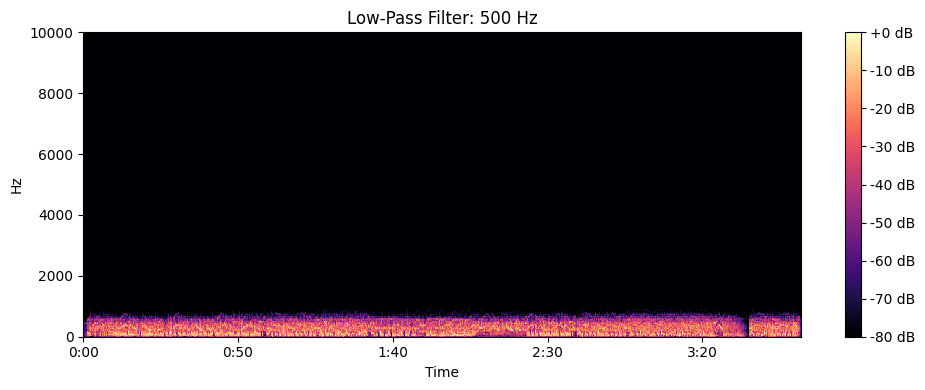

Saved low-pass audio: filtered_audio\lowpass_1500Hz.wav


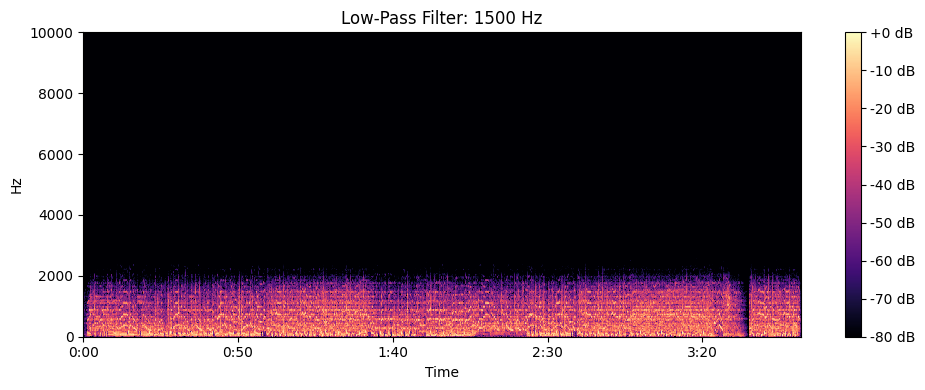

Saved low-pass audio: filtered_audio\lowpass_5000Hz.wav


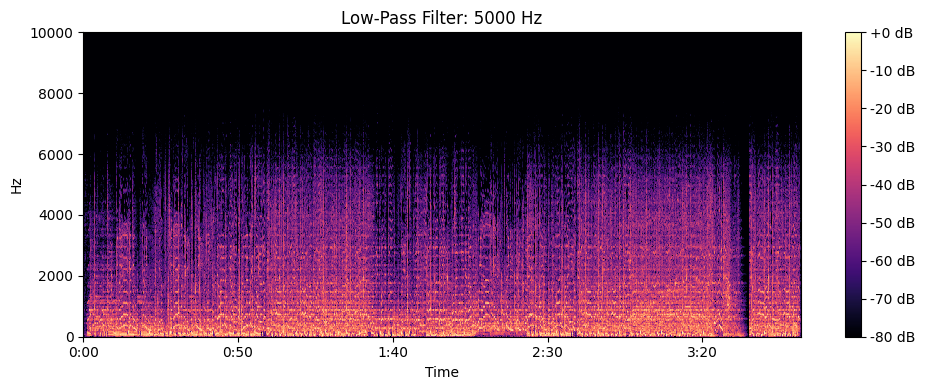

D:\python programming\ffmpeg\bin\ffmpeg.EXE

Audio processing completed successfully!
Check the filtered_audio folder for all output files.


In [6]:
import os
import librosa
import shutil
import subprocess
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from scipy.signal import butter, sosfiltfilt


# 1. Load Audio
filename = r"D:\SEM_5\DSIP\DSIP_practical\open_ended_problem_4\Tu Hi Disda.mpeg"

y, sr = librosa.load(filename, sr=None, mono=True)

print(f"Sample Rate: {sr} Hz")
print(f"Duration: {len(y) / sr:.2f} seconds")

# Create output folder
output_folder = "filtered_audio"
os.makedirs(output_folder, exist_ok=True)

# 2. Function to Apply Low-Pass Filter
def lowpass_filter(data, cutoff, fs, order=6):
    sos = butter(
        order,
        cutoff,
        btype="lowpass",
        fs=fs,
        output="sos"
    )
    return sosfiltfilt(sos, data)

# 3. Experiment with Three Cutoff Frequencies
cutoff_frequencies = [500, 1500, 5000]

for cutoff in cutoff_frequencies:
    filtered = lowpass_filter(y, cutoff, sr)

    output_path = os.path.join(
        output_folder, f"lowpass_{cutoff}Hz.wav"
    )

    sf.write(output_path, filtered, sr)

    print(f"Saved low-pass audio: {output_path}")

    # Plot spectrogram
    D = librosa.amplitude_to_db(
        np.abs(librosa.stft(filtered)),
        ref=np.max
    )

    plt.figure(figsize=(10, 4))
    librosa.display.specshow(
        D,
        sr=sr,
        x_axis="time",
        y_axis="hz"
    )
    plt.ylim(0, min(10000, sr / 2))
    plt.colorbar(format="%+2.0f dB")
    plt.title(f"Low-Pass Filter: {cutoff} Hz")
    plt.tight_layout()
    plt.show()

# 4. Function to Apply Band-Pass Filter
def bandpass_filter(data, lowcut, highcut, fs, order=6):
    sos = butter(
        order,
        [lowcut, highcut],
        btype="bandpass",
        fs=fs,
        output="sos"
    )
    return sosfiltfilt(sos, data)

# 5. Highlight Vocal Frequencies
vocal_band = bandpass_filter(
    y, 300, 3400, sr
)

# Estimate remaining audio components
background_estimate = y - vocal_band

# 6. Save Band-Pass Results as WAV
vocal_wav = os.path.join(
    output_folder, "estimated_vocals.wav"
)
background_wav = os.path.join(
    output_folder, "estimated_background.wav"
)

sf.write(vocal_wav, vocal_band, sr)
sf.write(background_wav, background_estimate, sr)

# 7. Convert WAV Files to MP3
ffmpeg_path = shutil.which("ffmpeg")
if ffmpeg_path is None:
    raise FileNotFoundError("FFmpeg was not found. Install FFmpeg and add it to PATH.")

for input_path, output_name in (
    (vocal_wav, "estimated_vocals.mp3"),
    (background_wav, "estimated_background.mp3"),
):
    subprocess.run(
        [
            ffmpeg_path,
            "-y",
            "-i",
            input_path,
            "-b:a",
            "192k",
            os.path.join(output_folder, output_name),
        ],
        check=True,
    )

print(ffmpeg_path)
print("\nAudio processing completed successfully!")
print("Check the filtered_audio folder for all output files.")